# Демо · Под капотом генерации

Лекция 3, слайд демо. Тезис: модель не «пишет», а на каждом шаге выдает распределение по словарю, а токен из него выбирает код. Все параметры генерации это способы выбирать.

Четыре шага:

0. Лосс на одном предложении: какую вероятность модель дала каждому настоящему токену.
1. Один forward pass руками: логиты, softmax, десять самых вероятных токенов, выбор, и так три раза.
2. Температура и зацикливание: одни логиты при трех температурах, жадная генерация уходит в цикл, top-p отрезает хвост.
3. Base против Instruct: один вопрос двум версиям одной модели.

Модель та же, что в лабораторных, `Qwen3-0.6B-Base`; в шаге 3 к ней добавляется чат-версия `Qwen3-0.6B`. Обе работают на CPU, на MPS быстрее. Картинки и тексты сохраняются в `fallback/`.

In [1]:
import os, time, math
from pathlib import Path
import torch
import torch.nn.functional as F
import matplotlib
import matplotlib.pyplot as plt
from transformers import AutoModelForCausalLM, AutoTokenizer

MODEL = os.environ.get("LAB_MODEL", "Qwen/Qwen3-0.6B-Base")
CHAT_MODEL = os.environ.get("LAB_CHAT_MODEL", "Qwen/Qwen3-0.6B")
HERE = Path.cwd()
FALLBACK = HERE / "fallback"
FALLBACK.mkdir(exist_ok=True)

device = (
    "cuda" if torch.cuda.is_available() 
    else "mps" if torch.backends.mps.is_available() 
    else "cpu"
)
tok = AutoTokenizer.from_pretrained(MODEL)
model = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.float32).to(device).eval()
print(MODEL, "на", device, "| словарь", len(tok), "| параметров", f"{sum(p.numel() for p in model.parameters()):,}")

plt.rcParams.update(
    {
        "font.family": "DejaVu Sans", 
        "axes.spines.top": False, 
        "axes.spines.right": False,
        "figure.dpi": 110, 
        "savefig.dpi": 150
    }
)
GRAY = "#333333"

def encode(text):
    return tok(
        text, 
        return_tensors="pt", 
        add_special_tokens=False
    )["input_ids"].to(device)

def bars(ax, labels, values, title, ylabel=None):
    ax.bar(range(len(labels)), values, color=GRAY)
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=60, ha="right", fontsize=9)
    ax.set_title(title, fontsize=11)
    if ylabel: ax.set_ylabel(ylabel)

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Qwen/Qwen3-0.6B-Base на mps | словарь 151669 | параметров 596,049,920


## 0. Лосс на одном предложении

Берем предложение из корпуса и спрашиваем модель про каждый токен: какую вероятность она дала бы настоящему следующему токену, зная все предыдущие. Минус логарифм этой вероятности и есть лосс на этой позиции. Среднее по позициям это число, которое уменьшают при обучении. Первый токен не оценивается, перед ним ничего нет.

На слайде этот пример показан для пяти токенов. Здесь он посчитан для настоящего предложения, и видно, за что модель платит дорого: за начало, за редкие слова и за места, где текст мог пойти куда угодно.

          'ня'  p =  0.000   -log p =  8.39
           'з'  p =  0.678   -log p =  0.39
           'ь'  p =  0.982   -log p =  0.02
       ' Андр'  p =  0.020   -log p =  3.92
          'ей'  p =  0.877   -log p =  0.13
         ' во'  p =  0.001   -log p =  6.86
         'шел'  p =  0.224   -log p =  1.50
          ' в'  p =  0.838   -log p =  0.18
     ' комнат'  p =  0.038   -log p =  3.26
           'у'  p =  0.987   -log p =  0.01
          ' и'  p =  0.176   -log p =  1.74
          ' с'  p =  0.061   -log p =  2.80
          'ел'  p =  0.317   -log p =  1.15
          ' у'  p =  0.045   -log p =  3.11
         ' ок'  p =  0.255   -log p =  1.37
          'на'  p =  0.983   -log p =  0.02
           '.'  p =  0.652   -log p =  0.43

средний лосс 2.075 нат, перплексия 8.0


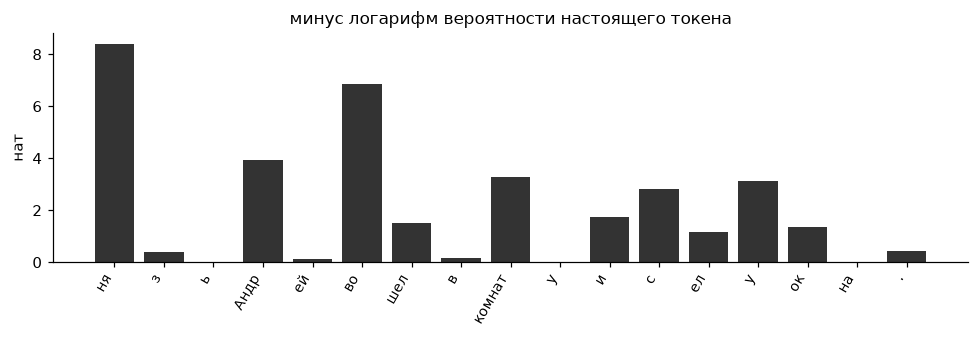

In [2]:
SENTENCE = "Князь Андрей вошел в комнату и сел у окна."
ids = encode(SENTENCE)
with torch.no_grad():
    logits = model(input_ids=ids).logits[0].float()
logp = F.log_softmax(logits, dim=-1)
targets = ids[0, 1:]
token_logp = logp[:-1].gather(1, targets[:, None])[:, 0].cpu()
labels = [tok.decode([t]) for t in targets.tolist()]
for lab, lp in zip(labels, token_logp.tolist()):
    print(f"{lab!r:>14}  p = {math.exp(lp):6.3f}   -log p = {-lp:5.2f}")
print(f"\nсредний лосс {(-token_logp.mean()).item():.3f} нат, перплексия {math.exp(-token_logp.mean().item()):.1f}")

fig, ax = plt.subplots(figsize=(9, 3.2))
bars(ax, labels, (-token_logp).tolist(), "минус логарифм вероятности настоящего токена", "нат")
fig.tight_layout(); fig.savefig(FALLBACK / "00_token_loss.png"); plt.show()

## 1. Один forward pass руками

Промпт в модель, на выходе логиты последней позиции: 151 936 чисел, по одному на токен словаря. Softmax превращает их в вероятности. Берем десять самых больших, смотрим, выбираем один, дописываем к промпту, повторяем. Это и есть генерация, ничего другого внутри `model.generate` нет.

Три шага вручную, на каждом печатается пятерка кандидатов и то, что выбрано жадно.

In [ ]:
PROMPT = "Князь Андрей вошел в комнату и"
ids = encode(PROMPT)
text = PROMPT
for step in range(3):
    with torch.no_grad():
        logits = model(input_ids=ids).logits[0, -1].float()
    probs = F.softmax(logits, dim=-1)
    top = torch.topk(probs, 5)
    print(f"шаг {step + 1}: ...{text[-40:]!r}")
    for p, i in zip(top.values.tolist(), top.indices.tolist()):
        print(f"      {tok.decode([i])!r:>12}  {p:.3f}")
    nxt = int(top.indices[0]) # жадный выбор: самый вероятный
    ids = torch.cat([ids, torch.tensor([[nxt]], device=device)], dim=1)
    text += tok.decode([nxt])
print("\nитог:", repr(text))

шаг 1: ...'Князь Андрей вошел в комнату и'
         ' сказал'  0.066
              ' с'  0.061
              ' у'  0.060
             ' по'  0.044
          ' начал'  0.033
шаг 2: ...'Князь Андрей вошел в комнату и сказал'
               ':'  0.510
               ','  0.112
          ' своем'  0.050
            ' ему'  0.018
          ' своим'  0.015
шаг 3: ...'Князь Андрей вошел в комнату и сказал:'
              ' "'  0.550
              ' «'  0.366
              ' “'  0.017
              " '"  0.008
              ' Я'  0.003

итог: 'Князь Андрей вошел в комнату и сказал: "'


## 2. Температура и зацикливание

Температура делит логиты перед softmax. При 0.3 распределение заостряется, почти вся масса на двух-трех токенах; при 1.0 распределение модели как есть; при 1.5 оно сплющивается, и хвост из тысяч маловероятных токенов начинает выпадать. Та же формула, что на первой лекции для биграмм.

T = 0.3: первый токен ' сказал' с вероятностью 0.323, на десятку приходится 0.97
T = 1.0: первый токен ' сказал' с вероятностью 0.066, на десятку приходится 0.39
T = 1.5: первый токен ' сказал' с вероятностью 0.028, на десятку приходится 0.19


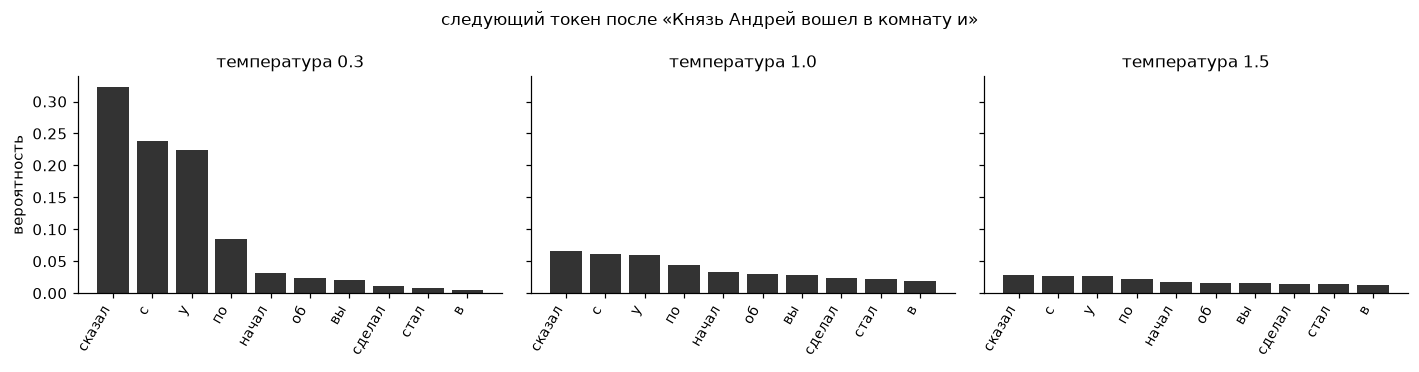

In [4]:
ids = encode(PROMPT)
with torch.no_grad():
    logits = model(input_ids=ids).logits[0, -1].float().cpu()
temps = (0.3, 1.0, 1.5)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, T in zip(axes, temps):
    probs = F.softmax(logits / T, dim=-1)
    top = torch.topk(probs, 10)
    bars(ax, [tok.decode([i]) for i in top.indices.tolist()], top.values.tolist(), f"температура {T}")
    print(f"T = {T}: первый токен {tok.decode([int(top.indices[0])])!r} с вероятностью {float(top.values[0]):.3f}, "
          f"на десятку приходится {float(top.values.sum()):.2f}")
axes[0].set_ylabel("вероятность")
fig.suptitle(f"следующий токен после «{PROMPT}»", fontsize=11)
fig.tight_layout(); fig.savefig(FALLBACK / "01_next_token.png"); plt.show()

Своя генерация в двадцать строк: температура, top-p, кэш ключей и значений. Это та же функция, что в лабораторной, только без top-k. С `use_cache` модель на каждом шаге получает один новый токен и `past_key_values`, без него пришлось бы подавать всю последовательность заново.

In [5]:
@torch.no_grad()
def generate(prompt, max_new_tokens, temperature=1.0, top_p=None, seed=0):
    ids = encode(prompt)
    gen = torch.Generator().manual_seed(seed)
    out = model(input_ids=ids, use_cache=True)
    new, nucleus = [], []
    for _ in range(max_new_tokens):
        logits = out.logits[0, -1].float().cpu()
        if temperature <= 0:
            nxt = int(logits.argmax())
        else:
            probs = F.softmax(logits / temperature, dim=-1)
            if top_p is not None:
                sp, order = torch.sort(probs, descending=True)
                keep = (sp.cumsum(0) - sp) <= top_p          # наименьший набор с суммой не меньше p
                nucleus.append(int(keep.sum()))
                probs = torch.zeros_like(probs).scatter(0, order[keep], sp[keep])
                probs /= probs.sum()
            nxt = int(torch.multinomial(probs, 1, generator=gen))
        new.append(nxt)
        if nxt == tok.eos_token_id:
            break
        out = model(input_ids=torch.tensor([[nxt]], device=device), past_key_values=out.past_key_values, use_cache=True)
    return tok.decode(new), new, nucleus

def loop_start(ids, n=4):
    seen = set()
    for i in range(n, len(ids) + 1):
        g = tuple(ids[i - n:i])
        if g in seen:
            return i - n
        seen.add(g)
    return None

Жадный выбор берет самый вероятный токен на каждом шаге и на длинном тексте уходит в цикл: повтор уже сказанного всегда правдоподобное продолжение, и выйти из него жадный выбор не может. Ниже четыре прогона с одной затравки: жадный, температура 0.7, температура 1.5 и top-p 0.9 при единичной температуре.

In [6]:
runs = [("жадный", 0.0, None), ("T = 0.7", 0.7, None), ("T = 1.5", 1.5, None), ("T = 1, top-p 0.9", 1.0, 0.9)]
lines = []
for name, T, p in runs:
    text, new, nucleus = generate(PROMPT, 80, temperature=T, top_p=p)
    note = ""
    if T == 0:
        ls = loop_start(new)
        note = f"  [цикл с токена {ls}]" if ls is not None else "  [цикла нет]"
    lines.append(f"{name}{note}\n{PROMPT}{text}\n")
    print(lines[-1])
(FALLBACK / "02_generation.txt").write_text("\n".join(lines), encoding="utf-8")

жадный  [цикл с токена 26]
Князь Андрей вошел в комнату и сказал: "Вот, пожалуйста, выслушайте меня. Я хочу, чтобы вы меня поняли. Я хочу, чтобы вы поняли, что я не хочу, чтобы вы меня убивали. Я хочу, чтобы вы поняли, что я не хочу, чтобы вы меня убивали. Я хочу, чтобы вы поняли,

T = 0.7
Князь Андрей вошел в комнату и висел на письменной ложке. Он начинал с самописных имен, и все буквы в номинальном окончании были в верхнем регистре. Он со сладким пламенем писал, и в его письмах всегда хрипло и гудело. Княз

T = 1.5
Князь Андрей вошел в комнату и вис меня на писше «его место обращ وحتىนิยมизм麽된다톢AYS постоя	gtkГвы всеУсердар(default环节но酹щен开着柈[ё绍兴朋菱悝騙税得了 운영štр顺Hel八十願意겝saysEn指导下 laid metextAlign me工透اسر..
ヾ英国 magnသรัฐบาลych yaptığıאנרג\uB立ちの overflow点了点头OSTรبه want	r�

T = 1, top-p 0.9
Князь Андрей вошел в комнату и висел на письменных ложках. Один из них была прямой и управляла электричеством. Второй — медленный и управляет нитями. Долго ли было до тех пор, пока его не услышат?

Долго

1063

Top-p отрезает хвост адаптивно: где модель уверена, в наборе один-два токена, где нет, сотни. График размера набора по шагам генерации показывает, как уверенность модели меняется по ходу текста.

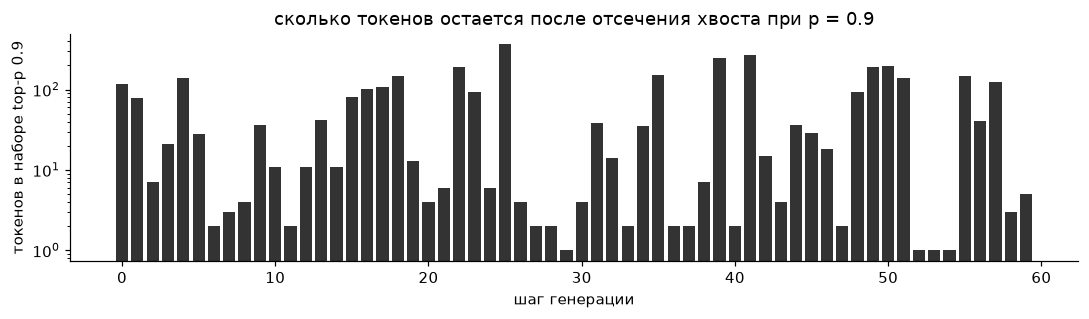

медиана 15 | максимум 365 | минимум 1
Князь Андрей вошел в комнату и висел на письменных ложках. Один из них была прямой и управляла электричеством. Второй — медленный и управляет нитями. Долго ли было до тех пор, пока его не услышат


In [7]:
text, new, nucleus = generate(PROMPT, 60, temperature=1.0, top_p=0.9)
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(range(len(nucleus)), nucleus, color=GRAY)
ax.set_yscale("log")
ax.set_xlabel("шаг генерации"); ax.set_ylabel("токенов в наборе top-p 0.9")
ax.set_title("сколько токенов остается после отсечения хвоста при p = 0.9")
fig.tight_layout(); fig.savefig(FALLBACK / "03_nucleus_size.png"); plt.show()
print("медиана", sorted(nucleus)[len(nucleus) // 2], "| максимум", max(nucleus), "| минимум", min(nucleus))
print(PROMPT + text)

## 3. Base против Instruct

Все, что было выше, делала Base-модель: она продолжает текст, потому что ее учили только этому. На вопрос она отвечает так, как продолжился бы текст с таким вопросом в корпусе: следующим вопросом, абзацем учебника или форумной перепалкой. Чат-версия той же модели прошла еще один этап обучения, о нем лекция 4, и на тот же вопрос отвечает. Здесь вопрос подается обеим: Base как есть, Instruct через шаблон чата с выключенным режимом размышлений.

In [ ]:
QUESTION = "Почему небо голубое?"
base_text, _, _ = generate(QUESTION, 80, temperature=0.7)
print("Base:", repr(QUESTION + base_text), "\n")

chat_tok = AutoTokenizer.from_pretrained(CHAT_MODEL)
chat = AutoModelForCausalLM.from_pretrained(CHAT_MODEL, dtype=torch.float32).to(device).eval()
prompt = chat_tok.apply_chat_template(
    [{"role": "user", "content": QUESTION}], 
    tokenize=False,
    add_generation_prompt=True, 
    enable_thinking=False
)

ids = chat_tok(prompt, return_tensors="pt").to(device)
with torch.no_grad():
    out = chat.generate(
        **ids, 
        max_new_tokens=120, 
        do_sample=True, 
        temperature=0.7, 
        top_p=0.9
)
chat_text = chat_tok.decode(
    out[0, ids["input_ids"].size(1):], 
    skip_special_tokens=True
)
print("Instruct:", repr(chat_text))
(FALLBACK / "04_base_vs_instruct.txt").write_text(f"Вопрос: {QUESTION}\n\nBase:\n{QUESTION}{base_text}\n\nInstruct:\n{chat_text}\n", encoding="utf-8")

Base: 'Почему небо голубое? Может ли меня суждение «небо голубое» означать, что я и все люди, которые видят его, имеют одну и ту же цветовую натуру? Какие существуют другие феномены, которые могут быть объяснены цветом неба?\n\nНебо голубое может быть объяснено несколькими фактор' 



Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Instruct: 'Небо голубое потому, что в небе солнечный свет проникает в атмосферу, а затем проходит через тёплые молекулы и поглощает его. Когда солнечный свет проходит через атмосферу, он поглощает некоторое количество синего и красного света, и оставляя осколки синего и красного, он поглощает остаток синего и красного в ат'


633

Между этими двумя ответами лежит вся четвертая лекция: что делают с Base-моделью, чтобы она отвечала, а не продолжала.